# Model Training and Evaluation

**Goal:** train at least three different classification models on a preprocessed dataset, evaluate them with Accuracy, Precision, Recall, F1 and a confusion matrix, and pick the best one with a justified argument.

**Notebook structure**
1. Setup and data loading
2. Model selection (with justification)
3. Data splitting (80/20, fixed random seed)
4. Model training (with parameter logging)
5. Model evaluation (metrics + confusion matrices)
6. Model comparison (table, plot, analysis, trade-offs)
7. Summary of findings

## 1. Setup and data loading

All randomness is controlled by a single `RANDOM_STATE` constant so the whole notebook is reproducible.

**Dataset.** By default the notebook uses the *Breast Cancer Wisconsin (Diagnostic)* dataset bundled with scikit-learn, so it runs anywhere without downloads. To use your own preprocessed dataset from the previous assignment, set `USE_OWN_DATA = True`, point `DATA_PATH` to the CSV and set `TARGET_COL`. The rest of the notebook works unchanged (binary or multi-class).

In [1]:
import json
import logging
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

ARTIFACTS_DIR = Path("artifacts")
ARTIFACTS_DIR.mkdir(exist_ok=True)

# Logging: everything goes both to the notebook output and to artifacts/training.log
logger = logging.getLogger("model_training")
logger.setLevel(logging.INFO)
logger.handlers.clear()
fmt = logging.Formatter("%(asctime)s | %(levelname)s | %(message)s", datefmt="%H:%M:%S")
for h in (logging.StreamHandler(), logging.FileHandler(ARTIFACTS_DIR / "training.log", mode="w")):
    h.setFormatter(fmt)
    logger.addHandler(h)
logger.info("Environment ready, RANDOM_STATE=%d", RANDOM_STATE)

23:19:05 | INFO | Environment ready, RANDOM_STATE=42


In [2]:
# ---- Data source configuration --------------------------------------------
USE_OWN_DATA = False                 # set True to use your own preprocessed CSV
DATA_PATH = "data/preprocessed.csv"  # path to your preprocessed dataset
TARGET_COL = "target"                # name of the label column
# -----------------------------------------------------------------------------

if USE_OWN_DATA:
    df = pd.read_csv(DATA_PATH)
    POSITIVE_LABEL = None  # chosen automatically below
else:
    raw = load_breast_cancer(as_frame=True)
    df = raw.frame.copy()
    # In the original encoding 0 = malignant, 1 = benign. We recode so that the
    # clinically important class (malignant) is the POSITIVE class (1):
    # precision / recall then describe how well we detect cancer.
    df[TARGET_COL] = (df["target"] == 0).astype(int)
    POSITIVE_LABEL = 1

X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]

print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Features: {X.shape[1]} | missing values: {int(df.isna().sum().sum())}")
df.head()

Shape: 569 rows x 31 columns
Features: 30 | missing values: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


Class distribution:
        count  share
target              
0         357  0.627
1         212  0.373

Binary task: True | metric averaging: binary | positive label: 1


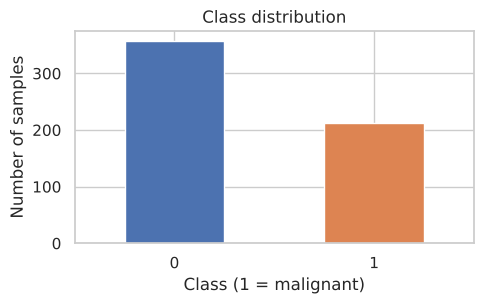

In [3]:
class_counts = y.value_counts().sort_index()
print("Class distribution:")
print(pd.DataFrame({"count": class_counts, "share": (class_counts / len(y)).round(3)}))

N_CLASSES = y.nunique()
IS_BINARY = N_CLASSES == 2
if IS_BINARY and POSITIVE_LABEL is None:
    POSITIVE_LABEL = class_counts.idxmin()  # minority class treated as positive
AVERAGE = "binary" if IS_BINARY else "weighted"
print(f"\nBinary task: {IS_BINARY} | metric averaging: {AVERAGE} | positive label: {POSITIVE_LABEL}")

fig, ax = plt.subplots(figsize=(5, 3.2))
class_counts.plot.bar(ax=ax, color=["#4C72B0", "#DD8452"][:N_CLASSES] if N_CLASSES <= 2 else None)
ax.set_title("Class distribution")
ax.set_xlabel("Class (1 = malignant)" if not USE_OWN_DATA else "Class")
ax.set_ylabel("Number of samples")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

In [4]:
X.describe().T[["mean", "std", "min", "max"]].head(10)

,mean,std,min,max
mean radius,14.127292,3.524049,6.98100,28.11000
mean texture,19.289649,4.301036,9.71000,39.28000
mean perimeter,91.969033,24.298981,43.79000,188.50000
mean area,654.889104,351.914129,143.50000,2501.00000
mean smoothness,0.096360,0.014064,0.05263,0.16340
mean compactness,0.104341,0.052813,0.01938,0.34540
mean concavity,0.088799,0.079720,0.00000,0.42680
mean concave points,0.048919,0.038803,0.00000,0.20120
mean symmetry,0.181162,0.027414,0.10600,0.30400
mean fractal dimension,0.062798,0.007060,0.04996,0.09744


**Dataset characteristics relevant for model choice**

- **569 samples, 30 numeric features**, no missing values, no categorical columns: the data is already clean and fully numeric.
- **Features live on very different scales** (e.g. `mean area` is in the hundreds/thousands, `mean smoothness` around 0.1). Distance- and margin-based models (SVM) and regularised linear models need **standardisation**; tree-based models do not.
- **Many features are strongly correlated** (radius, perimeter and area describe almost the same thing). This favours regularised models and ensembles, and makes a single deep tree prone to overfitting.
- **Moderate class imbalance** (~37% malignant / ~63% benign), so accuracy alone is not enough: we also look at precision, recall and F1, and use a **stratified** split.
- **Small dataset**: training is cheap, so we can also run 5-fold cross-validation to check that test-set results are not a lucky split.

## 2. Model selection

We train **four** models (the task requires at least three), chosen to cover different families of learning algorithms:

| Model | Family | Why it fits this dataset |
|---|---|---|
| **Logistic Regression** | Linear, probabilistic | Strong, interpretable baseline. Works well when classes are close to linearly separable (expected here: tumour size/shape features separate classes well). L2 regularisation handles correlated features. Requires scaling. |
| **Decision Tree** | Non-linear, rule-based | Fully interpretable (if/else rules), no scaling needed, captures interactions. Useful as a reference to see how much a single tree overfits on correlated features. |
| **Random Forest** | Ensemble (bagging of trees) | Fixes the high variance of a single tree by averaging many decorrelated trees; robust to correlated and unscaled features; gives feature importances. |
| **Support Vector Machine (RBF)** | Kernel, margin-based | Very effective on small/medium, high-dimensional numeric datasets; RBF kernel can model non-linear boundaries. Requires scaling. |

KNN was considered but not chosen: with 30 correlated features distances become less informative (curse of dimensionality), and SVM covers the same "geometric" niche more robustly.

For models that need scaling, the `StandardScaler` is placed **inside a `Pipeline`**, so it is fitted only on the training data and no information from the test set leaks into training.

## 3. Data splitting

80/20 split with `train_test_split`, fixed `random_state` for reproducibility and `stratify=y` so both sets keep the same class proportions.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

split_info = pd.DataFrame({
    "samples": [len(X_train), len(X_test)],
    "share_of_data": [len(X_train) / len(X), len(X_test) / len(X)],
    "positive_class_share": [y_train.mean() if IS_BINARY else np.nan, y_test.mean() if IS_BINARY else np.nan],
}, index=["train", "test"]).round(3)
logger.info("Split done: train=%d, test=%d (test_size=0.20, random_state=%d, stratified)",
            len(X_train), len(X_test), RANDOM_STATE)
split_info

23:19:05 | INFO | Split done: train=455, test=114 (test_size=0.20, random_state=42, stratified)


,samples,share_of_data,positive_class_share
train,455,0.8,0.374
test,114,0.2,0.368


## 4. Model training

Each model is defined with explicitly chosen hyperparameters. A helper function `train_model`:

1. fits the model on the training set and measures the training time,
2. **logs all parameters** (`model.get_params()`) to the log and to `artifacts/model_params.json`,
3. records 5-fold stratified cross-validation F1 on the training set (a robustness check, the test set is not touched).

If **MLflow** is installed, parameters and metrics are additionally logged as MLflow runs (optional, the notebook works without it).

In [6]:
try:
    import mlflow
    MLFLOW_AVAILABLE = True
    mlflow.set_experiment("model-training-and-evaluation")
except ImportError:
    MLFLOW_AVAILABLE = False
logger.info("MLflow available: %s", MLFLOW_AVAILABLE)

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
CV_SCORING = "f1" if IS_BINARY else "f1_weighted"
if IS_BINARY and POSITIVE_LABEL != 1:
    from sklearn.metrics import make_scorer
    CV_SCORING = make_scorer(f1_score, pos_label=POSITIVE_LABEL)

trained_models = {}
training_log = {}

def _jsonable(params):
    # keep only simple values so the params can be written to JSON / MLflow
    return {k: v for k, v in params.items() if isinstance(v, (int, float, str, bool, type(None)))}

def train_model(name, model):
    logger.info("=== Training %s ===", name)
    params = _jsonable(model.get_params())
    for k, v in sorted(params.items()):
        logger.info("  param %-35s = %s", k, v)

    cv_scores = cross_val_score(model, X_train, y_train, cv=CV, scoring=CV_SCORING)

    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_time = time.perf_counter() - start

    train_acc = accuracy_score(y_train, model.predict(X_train))
    logger.info("  fit time: %.3fs | train accuracy: %.4f | CV F1: %.4f +/- %.4f",
                fit_time, train_acc, cv_scores.mean(), cv_scores.std())

    trained_models[name] = model
    training_log[name] = {
        "params": params,
        "fit_time_s": round(fit_time, 4),
        "train_accuracy": round(train_acc, 4),
        "cv_f1_mean": round(cv_scores.mean(), 4),
        "cv_f1_std": round(cv_scores.std(), 4),
    }
    with open(ARTIFACTS_DIR / "model_params.json", "w") as f:
        json.dump(training_log, f, indent=2)
    return model

23:19:05 | INFO | MLflow available: False


### 4.1 Logistic Regression

- `StandardScaler` → features on the same scale (needed for regularisation and for the solver to converge).
- `C=1.0` – default L2 regularisation strength; a reasonable middle ground for correlated features.
- `solver="lbfgs"`, `max_iter=1000` – stable solver; more iterations to guarantee convergence.

In [7]:
log_reg = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(C=1.0, penalty="l2", solver="lbfgs",
                               max_iter=1000, random_state=RANDOM_STATE)),
])
train_model("Logistic Regression", log_reg)

23:19:05 | INFO | === Training Logistic Regression ===
23:19:05 | INFO |   param clf__C                              = 1.0
23:19:05 | INFO |   param clf__class_weight                   = None
23:19:05 | INFO |   param clf__dual                           = False
23:19:05 | INFO |   param clf__fit_intercept                  = True
23:19:05 | INFO |   param clf__intercept_scaling              = 1
23:19:05 | INFO |   param clf__l1_ratio                       = 0.0
23:19:05 | INFO |   param clf__max_iter                       = 1000
23:19:05 | INFO |   param clf__n_jobs                         = None
23:19:05 | INFO |   param clf__penalty                        = l2
23:19:05 | INFO |   param clf__random_state                   = 42
23:19:05 | INFO |   param clf__solver                         = lbfgs
23:19:05 | INFO |   param clf__tol                            = 0.0001
23:19:05 | INFO |   param clf__verbose                        = 0
23:19:05 | INFO |   param clf__warm_start               

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


### 4.2 Decision Tree

- No scaling (trees split on thresholds, scale does not matter).
- `max_depth=5`, `min_samples_leaf=5` – limit the tree's complexity; an unrestricted tree would memorise the training set (100% train accuracy) and generalise worse.
- `criterion="gini"` – standard impurity measure.

In [8]:
dec_tree = DecisionTreeClassifier(criterion="gini", max_depth=5, min_samples_leaf=5,
                                  random_state=RANDOM_STATE)
train_model("Decision Tree", dec_tree)

23:19:05 | INFO | === Training Decision Tree ===
23:19:05 | INFO |   param ccp_alpha                           = 0.0
23:19:05 | INFO |   param class_weight                        = None
23:19:05 | INFO |   param criterion                           = gini
23:19:05 | INFO |   param max_depth                           = 5
23:19:05 | INFO |   param max_features                        = None
23:19:05 | INFO |   param max_leaf_nodes                      = None
23:19:05 | INFO |   param min_impurity_decrease               = 0.0
23:19:05 | INFO |   param min_samples_leaf                    = 5
23:19:05 | INFO |   param min_samples_split                   = 2
23:19:05 | INFO |   param min_weight_fraction_leaf            = 0.0
23:19:05 | INFO |   param monotonic_cst                       = None
23:19:05 | INFO |   param random_state                        = 42
23:19:05 | INFO |   param splitter                            = best
23:19:05 | INFO |   fit time: 0.006s | train accuracy: 0.9626 | CV F

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

### 4.3 Random Forest

- `n_estimators=300` – enough trees for stable predictions (more trees only cost time).
- `max_features="sqrt"` – each split sees a random subset of features, which decorrelates the trees (important with correlated features).
- `min_samples_leaf=2` – light regularisation; `n_jobs=-1` uses all CPU cores.

In [9]:
rand_forest = RandomForestClassifier(n_estimators=300, max_features="sqrt", min_samples_leaf=2,
                                     random_state=RANDOM_STATE, n_jobs=-1)
train_model("Random Forest", rand_forest)

23:19:05 | INFO | === Training Random Forest ===
23:19:05 | INFO |   param bootstrap                           = True
23:19:05 | INFO |   param ccp_alpha                           = 0.0
23:19:05 | INFO |   param class_weight                        = None
23:19:05 | INFO |   param criterion                           = gini
23:19:05 | INFO |   param max_depth                           = None
23:19:05 | INFO |   param max_features                        = sqrt
23:19:05 | INFO |   param max_leaf_nodes                      = None
23:19:05 | INFO |   param max_samples                         = None
23:19:05 | INFO |   param min_impurity_decrease               = 0.0
23:19:05 | INFO |   param min_samples_leaf                    = 2
23:19:05 | INFO |   param min_samples_split                   = 2
23:19:05 | INFO |   param min_weight_fraction_leaf            = 0.0
23:19:05 | INFO |   param monotonic_cst                       = None
23:19:05 | INFO |   param n_estimators                        =

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

### 4.4 Support Vector Machine

- `StandardScaler` → mandatory for SVM (the RBF kernel is distance-based).
- `kernel="rbf"`, `C=1.0`, `gamma="scale"` – standard non-linear configuration; `gamma="scale"` adapts the kernel width to the data variance.
- `probability=True` – enables probability estimates (useful later, e.g. for ROC curves or threshold tuning).

In [10]:
svm = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", SVC(kernel="rbf", C=1.0, gamma="scale", probability=True,
                random_state=RANDOM_STATE)),
])
train_model("SVM (RBF)", svm)

23:19:09 | INFO | === Training SVM (RBF) ===
23:19:09 | INFO |   param clf__C                              = 1.0
23:19:09 | INFO |   param clf__break_ties                     = False
23:19:09 | INFO |   param clf__cache_size                     = 200
23:19:09 | INFO |   param clf__class_weight                   = None
23:19:09 | INFO |   param clf__coef0                          = 0.0
23:19:09 | INFO |   param clf__decision_function_shape        = ovr
23:19:09 | INFO |   param clf__degree                         = 3
23:19:09 | INFO |   param clf__gamma                          = scale
23:19:09 | INFO |   param clf__kernel                         = rbf
23:19:09 | INFO |   param clf__max_iter                       = -1
23:19:09 | INFO |   param clf__probability                    = True
23:19:09 | INFO |   param clf__random_state                   = 42
23:19:09 | INFO |   param clf__shrinking                      = True
23:19:09 | INFO |   param clf__tol                            = 0.00

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [11]:
# Training summary (parameters are stored in artifacts/model_params.json)
train_summary = pd.DataFrame({
    name: {k: v for k, v in info.items() if k != "params"} for name, info in training_log.items()
}).T
train_summary

,fit_time_s,train_accuracy,cv_f1_mean,cv_f1_std
Logistic Regression,0.0053,0.9868,0.9640,0.0207
Decision Tree,0.0061,0.9626,0.8979,0.0418
Random Forest,0.4731,0.9934,0.9434,0.0320
SVM (RBF),0.0151,0.9868,0.9610,0.0082


## 5. Model evaluation

All metrics are computed **on the test set only** (data the models have never seen).

- **Accuracy** – share of correct predictions.
- **Precision** – of the tumours predicted as malignant, how many really are malignant (few false alarms).
- **Recall** – of the truly malignant tumours, how many the model found (few missed cancers).
- **F1** – harmonic mean of precision and recall.

In [12]:
def evaluate(name, model):
    y_pred = model.predict(X_test)
    kw = {"average": AVERAGE, "zero_division": 0}
    if IS_BINARY:
        kw["pos_label"] = POSITIVE_LABEL
    return {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, **kw),
        "Recall": recall_score(y_test, y_pred, **kw),
        "F1 Score": f1_score(y_test, y_pred, **kw),
    }, y_pred

results, predictions = {}, {}
for name, model in trained_models.items():
    results[name], predictions[name] = evaluate(name, model)
    logger.info("%-20s | " + " | ".join(f"{k}: {{:.4f}}" for k in results[name]), name, *results[name].values())
    if MLFLOW_AVAILABLE:
        with mlflow.start_run(run_name=name):
            mlflow.log_params(training_log[name]["params"])
            mlflow.log_metrics({k.lower().replace(" ", "_"): v for k, v in results[name].items()})

--- Logging error ---
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/logging/__init__.py", line 1151, in emit
    msg = self.format(record)
  File "/usr/local/lib/python3.13/logging/__init__.py", line 999, in format
    return fmt.format(record)
           ~~~~~~~~~~^^^^^^^^
  File "/usr/local/lib/python3.13/logging/__init__.py", line 712, in format
    record.message = record.getMessage()
                     ~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/logging/__init__.py", line 400, in getMessage
    msg = msg % self.args
          ~~~~^~~~~~~~~~~
TypeError: not all arguments converted during string formatting
Call stack:
  File "/home/claude/build/run_notebook.py", line 59, in <module>
    exec(compile(tree, "<cell>", "exec"), ns)
  File "<cell>", line 16, in <module>
Message: '%-20s | Accuracy: {:.4f} | Precision: {:.4f} | Recall: {:.4f} | F1 Score: {:.4f}'
Arguments: ('Logistic Regression', 0.9649122807017544, 0.975, 0.9285714285714286, 0.9512195121

### 5.1 Detailed classification reports

In [13]:
target_names = ["benign (0)", "malignant (1)"] if not USE_OWN_DATA else None
for name, y_pred in predictions.items():
    print(f"===== {name} =====")
    print(classification_report(y_test, y_pred, target_names=target_names, digits=4))

===== Logistic Regression =====
               precision    recall  f1-score   support

   benign (0)     0.9595    0.9861    0.9726        72
malignant (1)     0.9750    0.9286    0.9512        42

     accuracy                         0.9649       114
    macro avg     0.9672    0.9573    0.9619       114
 weighted avg     0.9652    0.9649    0.9647       114

===== Decision Tree =====
               precision    recall  f1-score   support

   benign (0)     0.8961    0.9583    0.9262        72
malignant (1)     0.9189    0.8095    0.8608        42

     accuracy                         0.9035       114
    macro avg     0.9075    0.8839    0.8935       114
 weighted avg     0.9045    0.9035    0.9021       114

===== Random Forest =====
               precision    recall  f1-score   support

   benign (0)     0.9600    1.0000    0.9796        72
malignant (1)     1.0000    0.9286    0.9630        42

     accuracy                         0.9737       114
    macro avg     0.9800    

### 5.2 Confusion matrices

Rows = true class, columns = predicted class. For this problem the most costly cell is **true malignant → predicted benign** (a false negative = missed cancer).

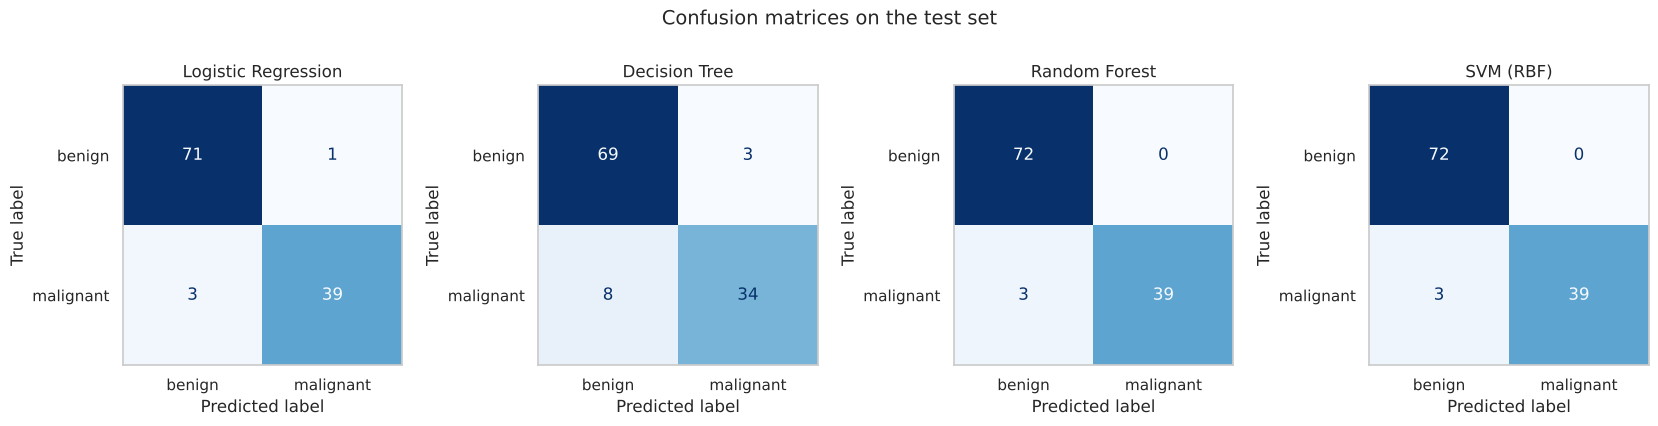

In [14]:
labels = sorted(y.unique())
display_labels = ["benign", "malignant"] if not USE_OWN_DATA else labels
fig, axes = plt.subplots(1, len(predictions), figsize=(4.2 * len(predictions), 4))
for ax, (name, y_pred) in zip(np.atleast_1d(axes), predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    ConfusionMatrixDisplay(cm, display_labels=display_labels).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    ax.grid(False)
plt.suptitle("Confusion matrices on the test set", y=1.03, fontsize=14)
plt.tight_layout()
fig.savefig(ARTIFACTS_DIR / "confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Model comparison

In [15]:
comparison = pd.DataFrame(results).T
comparison["CV F1 (train, mean)"] = [training_log[n]["cv_f1_mean"] for n in comparison.index]
comparison["CV F1 (train, std)"] = [training_log[n]["cv_f1_std"] for n in comparison.index]
comparison["Train Accuracy"] = [training_log[n]["train_accuracy"] for n in comparison.index]
comparison["Fit time (s)"] = [training_log[n]["fit_time_s"] for n in comparison.index]
if IS_BINARY:
    comparison["False Negatives"] = [int(((y_test == POSITIVE_LABEL) & (predictions[n] != POSITIVE_LABEL)).sum())
                                     for n in comparison.index]
    comparison["False Positives"] = [int(((y_test != POSITIVE_LABEL) & (predictions[n] == POSITIVE_LABEL)).sum())
                                     for n in comparison.index]
comparison = comparison.sort_values(["F1 Score", "Recall", "CV F1 (train, mean)"], ascending=False).round(4)
comparison.to_csv(ARTIFACTS_DIR / "model_comparison.csv")

best_model_name = comparison.index[0]
print(f"Best model (test F1, ties broken by recall and CV F1): {best_model_name}")
comparison.style.format(precision=4).highlight_max(
    subset=["Accuracy", "Precision", "Recall", "F1 Score"], color="#c6efce")

Best model (test F1, ties broken by recall and CV F1): SVM (RBF)


,Accuracy,Precision,Recall,F1 Score,"CV F1 (train, mean)","CV F1 (train, std)",Train Accuracy,Fit time (s),False Negatives,False Positives
SVM (RBF),0.9737,1.0000,0.9286,0.9630,0.9610,0.0082,0.9868,0.0151,3,0
Random Forest,0.9737,1.0000,0.9286,0.9630,0.9434,0.0320,0.9934,0.4731,3,0
Logistic Regression,0.9649,0.9750,0.9286,0.9512,0.9640,0.0207,0.9868,0.0053,3,1
Decision Tree,0.9035,0.9189,0.8095,0.8608,0.8979,0.0418,0.9626,0.0061,8,3


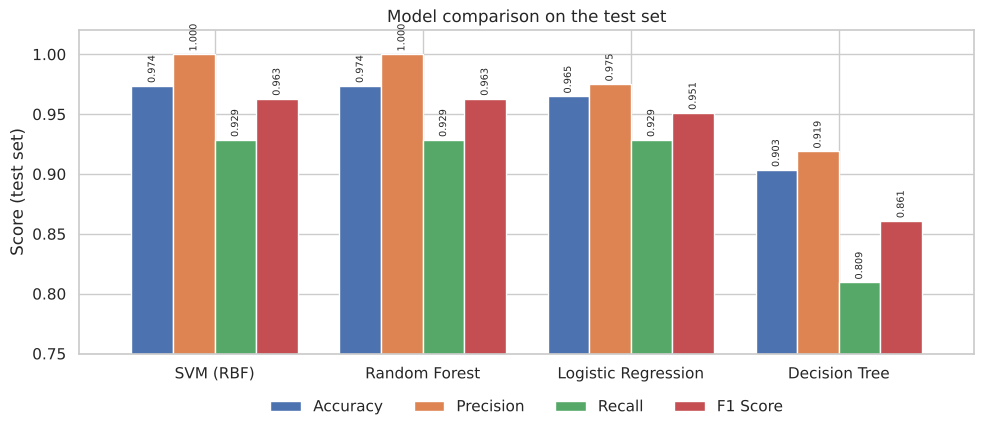

In [16]:
metric_cols = ["Accuracy", "Precision", "Recall", "F1 Score"]
ax = comparison[metric_cols].plot.bar(figsize=(10, 4.5), width=0.8)
ax.set_ylim(0.75, 1.02)
ax.set_ylabel("Score (test set)")
ax.set_title("Model comparison on the test set")
ax.tick_params(axis="x", rotation=0)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4, frameon=False)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=7, padding=2, rotation=90)
plt.tight_layout()
plt.gcf().savefig(ARTIFACTS_DIR / "model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

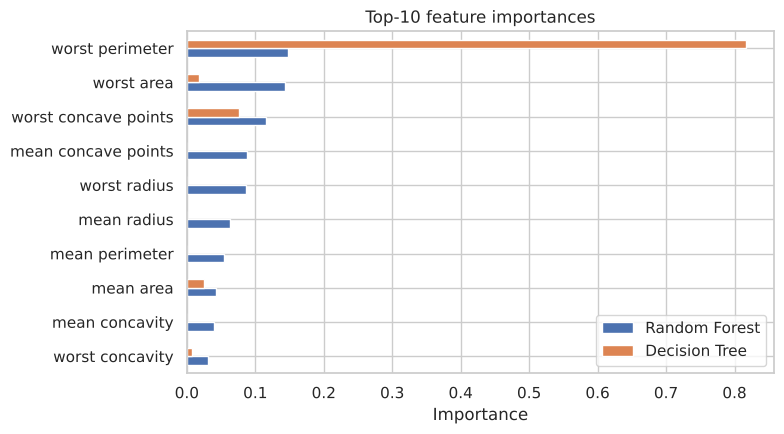

In [17]:
# Interpretability check: which features matter most for the tree-based models?
importances = pd.DataFrame({
    "Random Forest": trained_models["Random Forest"].feature_importances_,
    "Decision Tree": trained_models["Decision Tree"].feature_importances_,
}, index=X.columns).sort_values("Random Forest", ascending=False).head(10)

ax = importances[::-1].plot.barh(figsize=(8, 4.5))
ax.set_title("Top-10 feature importances")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

### 6.1 Analysis: which model performed best and why

**Results on the test set (114 samples, 42 malignant):**

| Model | Accuracy | Precision | Recall | F1 | CV F1 (5-fold, train) | FN / FP |
|---|---|---|---|---|---|---|
| **SVM (RBF)** | **0.974** | **1.000** | **0.929** | **0.963** | 0.961 ± 0.008 | 3 / 0 |
| Random Forest | **0.974** | **1.000** | **0.929** | **0.963** | 0.943 ± 0.032 | 3 / 0 |
| Logistic Regression | 0.965 | 0.975 | **0.929** | 0.951 | **0.964** ± 0.021 | 3 / 1 |
| Decision Tree | 0.904 | 0.919 | 0.810 | 0.861 | 0.898 ± 0.042 | 8 / 3 |

**Best model: SVM with RBF kernel.**

- SVM and Random Forest have **identical test results**: 97.4% accuracy, no false positives (precision = 1.0) and 3 missed malignant tumours (recall = 0.929). On the test set alone they cannot be separated.
- The tie is broken by **cross-validation on the training set**: SVM reaches CV F1 = 0.961 with the **lowest variance of all models (±0.008)**, while Random Forest has 0.943 ± 0.032. So SVM's performance is more stable across different data subsets and less dependent on one lucky split.
- **Why SVM works well here:** after standardisation, the 30 numeric features form a space in which the two classes are separated by a smooth, almost linear boundary. The RBF kernel with maximum-margin training finds such a boundary and is robust to correlated features, which is exactly the setting where SVMs excel (small, clean, numeric, medium-dimensional data).
- **Logistic Regression** is very close (only 1 more false positive on the test set, and even the best CV F1). This confirms that the problem is almost linearly separable — the extra flexibility of the RBF kernel gives only a small gain.
- **Decision Tree** is clearly the weakest: it misses 8 of 42 malignant tumours (recall 0.81). A single tree uses only a few features (almost all splits rely on `worst perimeter`, importance 0.82) and creates axis-aligned, step-like boundaries; it has the highest variance in CV (±0.042). Random Forest fixes exactly this weakness by averaging 300 trees and spreading importance across many correlated features (`worst perimeter`, `worst area`, `worst concave points`, ...), which raises F1 from 0.861 to 0.963.

### 6.2 Trade-offs

- **Performance vs. interpretability.** Logistic Regression and the Decision Tree are easy to explain (coefficients / if-else rules), which matters in medicine. SVM with an RBF kernel and Random Forest are more accurate but act more like black boxes. If explainability were a hard requirement, **Logistic Regression** would be the best compromise: it loses only one test prediction compared to SVM.
- **Precision vs. recall.** All top models have perfect precision but miss 3 malignant cases. In cancer screening a false negative is far more costly than a false alarm, so in practice we would **lower the decision threshold** (e.g. using SVM's `predict_proba`) or set `class_weight="balanced"` to raise recall at the cost of some precision.
- **Training and prediction cost.** Logistic Regression and SVM train in milliseconds; Random Forest with 300 trees is the slowest to train and predict and produces the largest model. On larger datasets the picture changes: SVM scales poorly (roughly quadratic in the number of samples), while Random Forest parallelises well.
- **Preprocessing requirements.** SVM and Logistic Regression **require feature scaling** (handled inside the pipeline); tree-based models work on raw features and are more robust to outliers and mixed feature types.
- **Stability.** A single Decision Tree is sensitive to small changes in the data (high CV variance); ensembles and margin-based models are much more stable.

## Summary of findings

1. Four models from different families were trained on an 80/20 stratified split (`random_state=42`), with all hyperparameters logged to `artifacts/training.log` and `artifacts/model_params.json`.
2. **SVM (RBF)** and **Random Forest** achieved the best test performance (accuracy 0.974, precision 1.000, recall 0.929, F1 0.963); **SVM is selected as the best model** because it matches Random Forest on the test set, has a higher and much more stable cross-validation F1 (0.961 ± 0.008), and is far cheaper to train.
3. Logistic Regression is a very strong, interpretable alternative (F1 0.951), showing the data is almost linearly separable. The Decision Tree is the weakest (F1 0.861, 8 missed cancers) because of its high variance and reliance on a single feature.
4. For a real diagnostic use case, the next step would be tuning the decision threshold / class weights of the SVM to reduce false negatives, and hyperparameter search (e.g. `GridSearchCV` over `C` and `gamma`).

## 7. Saved artifacts

| File | Content |
|---|---|
| `artifacts/training.log` | Full training log with every model parameter |
| `artifacts/model_params.json` | Parameters, fit time, train accuracy and CV score per model |
| `artifacts/model_comparison.csv` | Comparison table |
| `artifacts/confusion_matrices.png`, `artifacts/model_comparison.png` | Plots |